In [17]:
# Task 2: California Housing Price Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


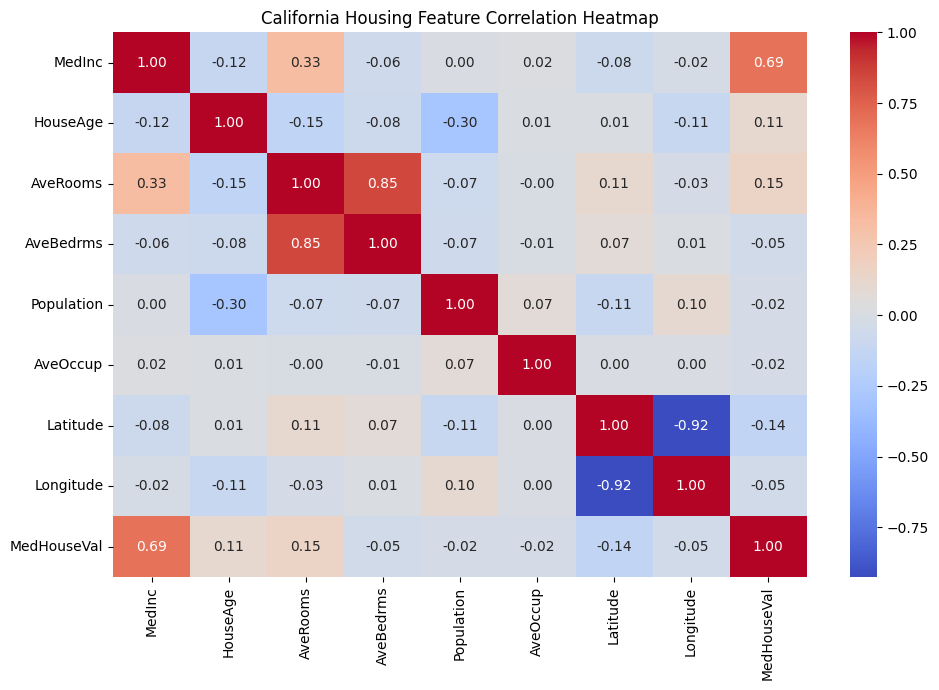

In [19]:
# Exploratory Data Analysis (EDA)

print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("California Housing Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
# Handle missing values, create interaction features, and split data

# Separate features and target
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

# Create interaction features
poly = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_interactions = poly.fit_transform(X)
feature_names = poly.get_feature_names_out(X.columns)

X = pd.DataFrame(X_interactions, columns=feature_names)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Features after interaction engineering:", X_train.shape[1])

Training rows: 16512
Testing rows: 4128
Features after interaction engineering: 36


In [21]:
# Build and tune OLS, Ridge, and Lasso regression models

models = {
    "OLS": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": GridSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        {"model__alpha": [0.1, 1, 10, 100]},
        cv=3,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    ),

    "Lasso": GridSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Lasso(max_iter=20000))
        ]),
        {"model__alpha": [0.001, 0.01, 0.1, 1]},
        cv=3,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
}

results = []
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    best_model = model.best_estimator_ if isinstance(model, GridSearchCV) else model
    y_pred = best_model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2 Score": r2_score(y_test, y_pred),
        "Best Alpha": (
            model.best_params_["model__alpha"]
            if isinstance(model, GridSearchCV) else "N/A"
        )
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(4))

Training OLS...
Training Ridge...
Training Lasso...


,Model,RMSE,MAE,R2 Score,Best Alpha
0,OLS,0.7033,0.4809,0.6225,N/A
1,Ridge,0.7440,0.5202,0.5776,100
2,Lasso,0.7514,0.5329,0.5692,0.01


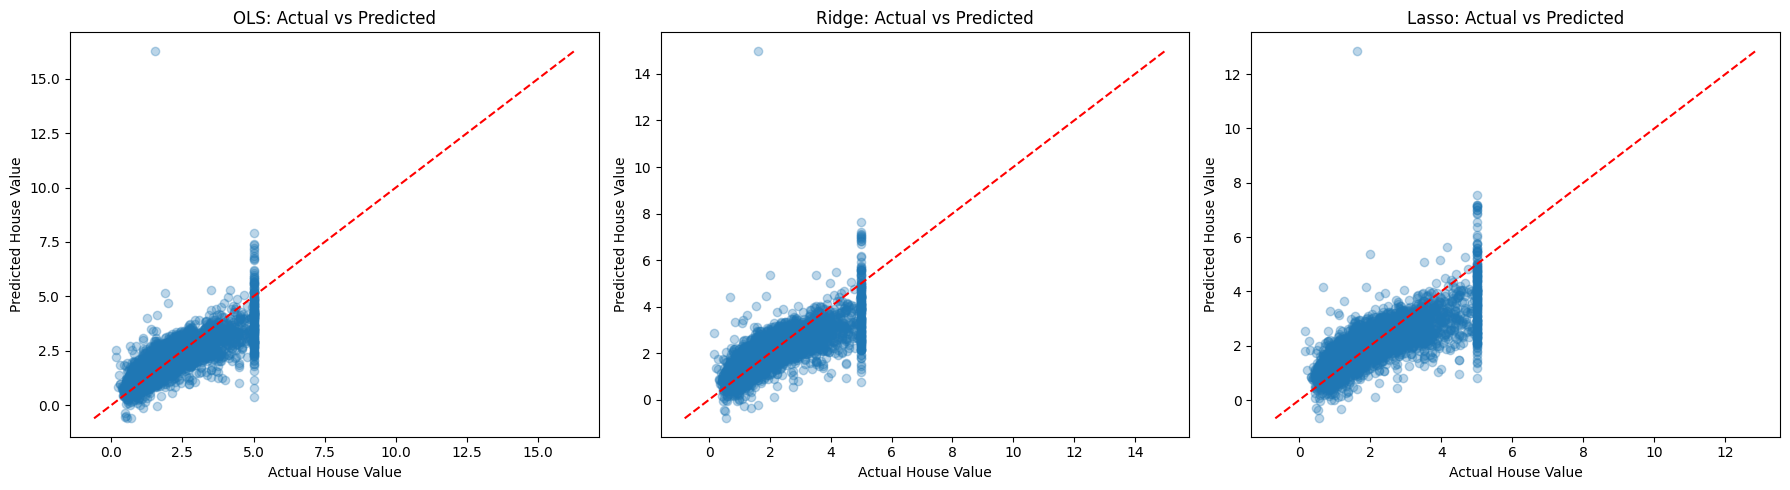

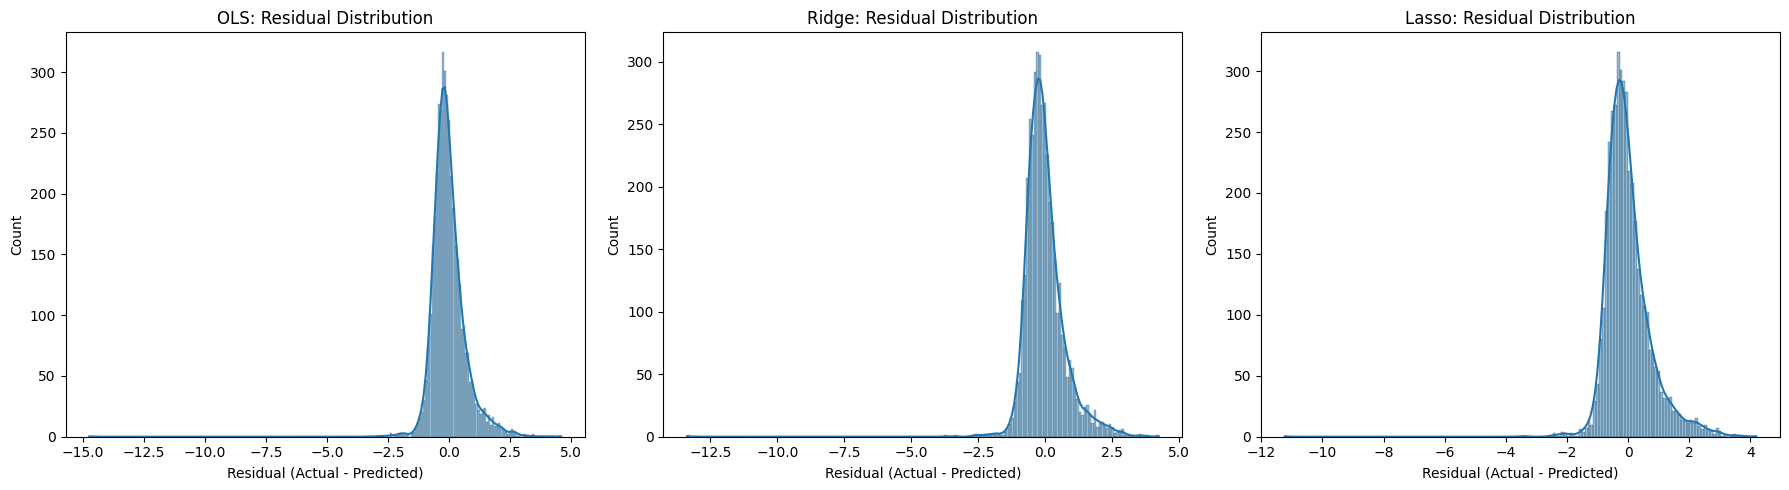

In [22]:
# Predicted vs Actual plots and residual analysis

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3)
    limits = [
        min(y_test.min(), y_pred.min()),
        max(y_test.max(), y_pred.max())
    ]
    ax.plot(limits, limits, "r--")
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.tight_layout()
plt.show()

# Residual distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=ax)
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()